# 12 — Part 2 final evaluation on 2015–2018 (temporal test)
**Plan:** [`docs/part2_plan.md`](../docs/part2_plan.md) §7, including the change log, which was committed before this notebook was run.

- This is the **only** notebook that uses 2015–2018 outcomes. The models, features and thresholds are the ones saved in notebook 11.
  Nothing here changes them.
- **Confidence intervals:** survey-design bootstrap (Rao–Wu, one PSU per stratum counted twice; `src/part2_eval.py`). 5,000 resamples
  (seed 42) for the main analyses, and 2,000 for subgroup tables.
- Section numbers (§7.x) refer to the plan.

In [1]:
import sys, json
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy.special import logit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.calibration import calibration_curve

from src.data import PROJECT_ROOT
from src.models import sensitivity_at_rate, gradient_boosting
from src.part2_data import load
from src.part2_models import TARGETS, CHAIN_FEATURE, add_diabetes_risk
from src.part2_eval import bootstrap_indices, percentile_ci

sns.set_theme(style="whitegrid")
train, test = load("train"), load("test")
meta = json.loads((PROJECT_ROOT / "models" / "part2" / "metadata.json").read_text())
model = {k: joblib.load(PROJECT_ROOT / v["file"]) for k, v in meta["models"].items()}
D, K = TARGETS["diabetes"], TARGETS["ckd"]

test = test.copy()
test["p_diab"] = model["diabetes"].predict_proba(test[meta["models"]["diabetes"]["features"]])[:, 1]
test["p_ckd"] = model["ckd"].predict_proba(test[meta["models"]["ckd"]["features"]])[:, 1]
dpop, kpop = test[test[D["target"]].notna()], test[test[K["target"]].notna()]
for name, pop, t in [("diabetes", dpop, D), ("kidney", kpop, K)]:
    print(f"{name:8s}: {len(pop):,} adults, {int(pop[t['target']].sum()):,} cases ({pop[t['target']].mean():.1%}), {pop.cluster.nunique()} PSUs")

diabetes: 8,523 adults, 343 cases (4.0%), 60 PSUs
kidney  : 9,525 adults, 1,624 cases (17.0%), 60 PSUs


In [2]:
def boot(df, fn, n_boot=5000, seed=42):
    """Point estimate, 95 % CI and share of resamples > 0, for a statistic fn(df) under the survey-design bootstrap."""
    vals = [fn(df.iloc[i]) for i in bootstrap_indices(df["cluster"].to_numpy(), n_boot=n_boot, seed=seed)]
    lo, hi = percentile_ci(vals)
    return {"estimate": fn(df), "CI low": lo, "CI high": hi, "share > 0": float(np.mean(np.array(vals) > 0))}

def caught(df, target, score, rate):
    return sensitivity_at_rate(df[target].to_numpy(), df[score].to_numpy().astype(float), rate)

def model_minus_rule(target, score, rule):
    def fn(df):
        rate = df[rule].mean()
        return caught(df, target, score, rate) - caught(df, target, rule, rate)
    return fn

## §7.1 Primary results

In [3]:
rows = []
for label, pop, t, score in [("P1 Diabetes: model vs CDC/ADA score ≥ 5", dpop, D, "p_diab"),
                             ("P2 Kidney: model vs KDIGO priority groups", kpop, K, "p_ckd")]:
    rate = pop[t["rule"]].mean()
    r = boot(pop, model_minus_rule(t["target"], score, t["rule"]))
    rows.append({"question": label, "baseline refers": f"{rate:.1%}",
                 "baseline catches": f"{caught(pop, t['target'], t['rule'], rate):.3f}",
                 "model catches": f"{caught(pop, t['target'], score, rate):.3f}",
                 "difference (95% CI)": f"{r['estimate']:+.3f} ({r['CI low']:+.3f} to {r['CI high']:+.3f})",
                 "criterion met": "YES" if r["CI low"] > 0 else "NO"})
primary = pd.DataFrame(rows).set_index("question")
primary

,baseline refers,baseline catches,model catches,difference (95% CI),criterion met
question,,,,,
P1 Diabetes: model vs CDC/ADA score ≥ 5,42.9%,0.816,0.813,-0.003 (-0.042 to +0.036),NO
P2 Kidney: model vs KDIGO priority groups,49.6%,0.800,0.825,+0.025 (+0.010 to +0.040),YES


**P1 (diabetes): not met.** At the CDC/ADA score's referral rate (43 %), the model catches **81.3 %** of undiagnosed diabetes and the
score catches **81.6 %**: a difference of −0.3 points (95 % CI −4.2 to +3.6). The small edge seen in cross-validation (+1.4) didn't hold up in
later years. **The official CDC/ADA questionnaire is as good as the model at finding undiagnosed diabetes.** That's a useful negative result:
a simple, free, seven-question score already does this job well.

**P2 (kidney): met.** At the KDIGO groups' referral rate (50 %), the model catches **82.5 %** of undiagnosed kidney markers and the groups
catch **80.0 %**: **+2.5 points (95 % CI +1.0 to +4.0)**. The advantage seen in training carried over to 2015–2018.

## §7.2 Secondary results
### Discrimination and calibration

In [4]:
def slope(y, p):
    lp = logit(np.clip(p, 1e-6, 1 - 1e-6)).reshape(-1, 1)
    return LogisticRegression(C=1e12).fit(lp, y).coef_[0, 0]

rows = []
for name, pop, t, score in [("Diabetes", dpop, D, "p_diab"), ("Kidney", kpop, K, "p_ckd")]:
    y = pop[t["target"]].to_numpy()
    auc_diff = boot(pop, lambda d: roc_auc_score(d[t["target"]], d[score]) - roc_auc_score(d[t["target"]], d[t["rule_score"]]))
    rows.append({"target": name, "model ROC-AUC": roc_auc_score(y, pop[score]),
                 "baseline ROC-AUC": roc_auc_score(y, pop[t["rule_score"]]),
                 "AUC difference (95% CI)": f"{auc_diff['estimate']:+.3f} ({auc_diff['CI low']:+.3f} to {auc_diff['CI high']:+.3f})",
                 "model PR-AUC": average_precision_score(y, pop[score]), "Brier": brier_score_loss(y, pop[score]),
                 "mean predicted": pop[score].mean(), "observed rate": y.mean(), "calibration slope": slope(y, pop[score].to_numpy())})
pd.DataFrame(rows).set_index("target").round(3)

,model ROC-AUC,baseline ROC-AUC,AUC difference (95% CI),model PR-AUC,Brier,mean predicted,observed rate,calibration slope
target,,,,,,,,
Diabetes,0.763,0.751,+0.012 (+0.001 to +0.023),0.100,0.038,0.043,0.04,0.827
Kidney,0.788,0.683,+0.105 (+0.096 to +0.114),0.466,0.116,0.181,0.17,0.940


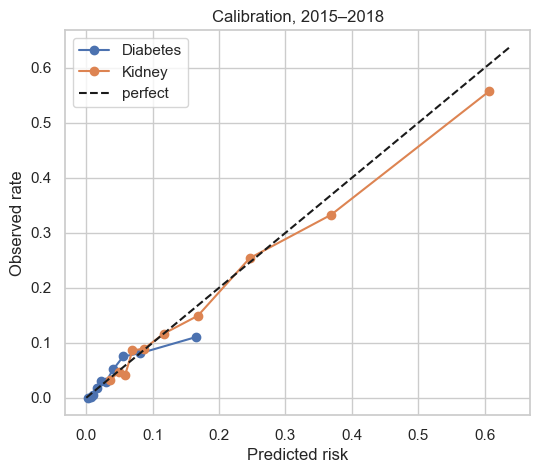

In [5]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, pop, t, score in [("Diabetes", dpop, D, "p_diab"), ("Kidney", kpop, K, "p_ckd")]:
    fp, mp = calibration_curve(pop[t["target"]], pop[score], n_bins=10, strategy="quantile")
    ax.plot(mp, fp, "o-", label=name)
lim = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.plot([0, lim], [0, lim], "k--", label="perfect")
ax.set_xlabel("Predicted risk"); ax.set_ylabel("Observed rate"); ax.set_title("Calibration, 2015–2018"); ax.legend()
plt.show()

- **Ranking:** the diabetes model's ROC-AUC (0.763) is slightly above the CDC/ADA score's (0.751), +0.012 (95 % CI +0.001 to +0.023). So it
  ranks people a little better overall, but not at the referral rate that matters (P1). The kidney model ranks far better than the KDIGO groups:
  **0.788 vs 0.683** (+0.105, 95 % CI +0.096 to +0.114).
- **Calibration held up over time** (unlike Part 1 across populations). Mean predicted risk is 4.3 % vs 4.0 % observed (diabetes), and 18.1 % vs
  17.0 % (kidney). The slopes are 0.83 and 0.94, so diabetes predictions are somewhat too spread out. Both models slightly overestimate risk in
  the later years, which fits the older test population found in the audit.

### Saved thresholds, used unchanged

In [6]:
rows = []
for name, pop, t, score in [("Diabetes", dpop, D, "p_diab"), ("Kidney", kpop, K, "p_ckd")]:
    y = pop[t["target"]].to_numpy()
    for th_name, th in meta["models"]["diabetes" if name == "Diabetes" else "ckd"]["thresholds"].items():
        ref = pop[score].to_numpy() >= th
        rows.append({"target": name, "method": f"model, {th_name}", "refers": ref.mean(), "catches": ref[y == 1].mean(), "PPV": y[ref].mean()})
    ref = pop[t["rule"]].to_numpy() == 1
    rows.append({"target": name, "method": f"baseline ({t['rule']})", "refers": ref.mean(), "catches": ref[y == 1].mean(), "PPV": y[ref].mean()})
pd.DataFrame(rows).set_index(["target", "method"]).round(3)

refers  catches    PPV
target   method                                          
Diabetes model, matched_rate        0.447    0.828  0.075
         model, high_sensitivity    0.408    0.799  0.079
         baseline (CDCHighRisk)     0.429    0.816  0.077
Kidney   model, matched_rate        0.499    0.827  0.282
         model, high_sensitivity    0.476    0.817  0.292
         baseline (KDIGOPriority)   0.496    0.800  0.275

The saved standard thresholds now refer slightly **more** people than intended (diabetes 44.7 % vs ~40 % in training; kidney 49.9 % vs ~46 %),
because the 2015–2018 population is older and higher-risk (audit, notebook 10). The baselines shifted in the same way (CDC 42.9 %, KDIGO
49.6 %). At those thresholds the kidney model catches 82.7 % with a PPV of 28.2 %, while KDIGO catches 80.0 % with a PPV of 27.5 %. For
diabetes, the model and the CDC score are again nearly identical.

### Other baselines and targets
- **Diabetes vs the USPSTF-style rule** (age 35–70 and BMI ≥ 25), at that rule's referral rate.
- **Prediabetes or diabetes** (HbA1c ≥ 5.7 %): the diabetes model vs the CDC/ADA score, which was designed for this target.
- **Sensitivity check:** kidney target defined by **eGFR < 60 only** (logged in the plan before modelling).

In [7]:
rows = []
dys = test[test.UndxDysglycemia.notna()]
egfr = kpop[kpop.eGFR.notna()].assign(LowEGFR=lambda d: (d.eGFR < 60).astype(float))
for label, pop, target, score, rule in [
    ("Diabetes: model vs USPSTF-style rule", dpop, D["target"], "p_diab", "USPSTFRule"),
    ("Prediabetes/diabetes: model vs CDC/ADA ≥ 5", dys, "UndxDysglycemia", "p_diab", "CDCHighRisk"),
    ("Kidney, eGFR < 60 only: model vs KDIGO", egfr, "LowEGFR", "p_ckd", "KDIGOPriority"),
]:
    rate = pop[rule].mean()
    r = boot(pop, model_minus_rule(target, score, rule))
    rows.append({"comparison": label, "cases": int(pop[target].sum()), "baseline refers": f"{rate:.1%}",
                 "baseline catches": f"{caught(pop, target, rule, rate):.3f}", "model catches": f"{caught(pop, target, score, rate):.3f}",
                 "difference (95% CI)": f"{r['estimate']:+.3f} ({r['CI low']:+.3f} to {r['CI high']:+.3f})",
                 "model ROC-AUC": round(roc_auc_score(pop[target], pop[score]), 3)})
pd.DataFrame(rows).set_index("comparison")

,cases,baseline refers,baseline catches,model catches,difference (95% CI),model ROC-AUC
comparison,,,,,,
Diabetes: model vs USPSTF-style rule,343,44.3%,0.644,0.825,+0.181 (+0.103 to +0.257),0.763
Prediabetes/diabetes: model vs CDC/ADA ≥ 5,3026,42.9%,0.659,0.649,-0.010 (-0.021 to +0.001),0.739
"Kidney, eGFR < 60 only: model vs KDIGO",597,49.3%,0.911,0.958,+0.047 (+0.025 to +0.069),0.866


- **The USPSTF-style rule from Part 1 is much weaker** than the CDC/ADA score. At its own referral rate the model catches 18 points more cases
  (82.5 % vs 64.4 %). This confirms the professional review's criticism of Part 1's baseline. Against the proper questionnaire, the advantage disappears.
- **Prediabetes or diabetes (HbA1c ≥ 5.7 %):** the CDC/ADA score, which was designed for this target, is as good as the model or slightly better
  (−1.0 points, 95 % CI −2.1 to +0.1).
- **Kidney, eGFR < 60 only** (the stricter definition, without single-test albumin): the model's advantage over KDIGO **grows** to +4.7 points
  (95 % CI +2.5 to +6.9), with ROC-AUC 0.866. So the kidney result isn't an artefact of the noisy albumin test.

## §7.3 Interconnection
### 7.3.1 How the conditions overlap in 2015–2018

In [8]:
both = test[test.UndxDiabetes.notna() & test.UndxCKD.notna()].copy()
print(f"Adults in both target populations: {len(both):,}")
pd.DataFrame({
    "CKD markers %": [both.loc[both.UndxDiabetes == v, "UndxCKD"].mean() * 100 for v in [0, 1]] +
                     [both.loc[both.Hypertension == v, "UndxCKD"].mean() * 100 for v in [0, 1]],
    "undiagnosed diabetes %": [np.nan, np.nan] + [both.loc[both.Hypertension == v, "UndxDiabetes"].mean() * 100 for v in [0, 1]],
    "n": [int((both.UndxDiabetes == v).sum()) for v in [0, 1]] + [int((both.Hypertension == v).sum()) for v in [0, 1]],
}, index=["no undiagnosed diabetes", "undiagnosed diabetes", "no hypertension", "hypertension"]).round(1)

Adults in both target populations: 8,088


,CKD markers %,undiagnosed diabetes %,n
no undiagnosed diabetes,12.5,NaN,7771
undiagnosed diabetes,29.3,NaN,317
no hypertension,7.1,2.3,4955
hypertension,22.8,6.5,3133


### 7.3.2 Does predicted diabetes risk help the kidney model? (pre-registered)
The kidney model with the diabetes-risk input is refitted on 2007–2014, exactly as in notebook 11, and compared on 2015–2018.

In [9]:
k_feats = meta["models"]["ckd"]["features"] + [CHAIN_FEATURE]
train_chain, test_chain = add_diabetes_risk(train, test)
fit_rows = train_chain[train_chain[K["target"]].notna()]
chain_model = gradient_boosting(k_feats).fit(fit_rows[k_feats], fit_rows[K["target"]])
kpop = kpop.assign(p_ckd_chain=chain_model.predict_proba(test_chain.loc[kpop.index, k_feats])[:, 1])
r = boot(kpop, lambda d: roc_auc_score(d[K["target"]], d.p_ckd_chain) - roc_auc_score(d[K["target"]], d.p_ckd))
print(f"Kidney ROC-AUC without diabetes risk: {roc_auc_score(kpop[K['target']], kpop.p_ckd):.4f}")
print(f"Kidney ROC-AUC with diabetes risk:    {roc_auc_score(kpop[K['target']], kpop.p_ckd_chain):.4f}")
print(f"Difference {r['estimate']:+.4f} (95% CI {r['CI low']:+.4f} to {r['CI high']:+.4f})  ->",
      "helps" if r["CI low"] > 0 else "no evidence it helps")

Kidney ROC-AUC without diabetes risk: 0.7884
Kidney ROC-AUC with diabetes risk:    0.7886
Difference +0.0002 (95% CI -0.0012 to +0.0015)  -> no evidence it helps


### 7.3.3 One blood draw for both tests
Guideline policy: refer for both tests if CDC/ADA ≥ 5 **or** in a KDIGO priority group. Model policy: refer the same number of people, ranked
by the larger of their two threshold-scaled risks (plan change log).

In [10]:
t_d = meta["models"]["diabetes"]["thresholds"]["matched_rate"]
t_k = meta["models"]["ckd"]["thresholds"]["matched_rate"]
both = both.assign(combined=np.maximum(both.p_diab / t_d, both.p_ckd / t_k),
                   guideline=((both.CDCHighRisk == 1) | (both.KDIGOPriority == 1)).astype(float))

def policy_stats(d, refer):
    found = d.loc[refer, "UndxDiabetes"].sum() + d.loc[refer, "UndxCKD"].sum()
    total = d.UndxDiabetes.sum() + d.UndxCKD.sum()
    return found / refer.sum() * 100, found / total

def model_refers(d):
    k = int(round(d.guideline.mean() * len(d)))
    refer = np.zeros(len(d), dtype=bool)
    refer[np.argsort(-d.combined.to_numpy(), kind="stable")[:k]] = True
    return pd.Series(refer, index=d.index)

def diff_found(d):
    return policy_stats(d, model_refers(d))[1] - policy_stats(d, d.guideline == 1)[1]

g_per100, g_share = policy_stats(both, both.guideline == 1)
m_per100, m_share = policy_stats(both, model_refers(both))
r = boot(both, diff_found)
print(f"Both policies refer {both.guideline.mean():.1%} of adults")
print(f"Guideline: {g_per100:.1f} conditions found per 100 referrals, {g_share:.1%} of all undiagnosed conditions found")
print(f"Models:    {m_per100:.1f} conditions found per 100 referrals, {m_share:.1%} of all undiagnosed conditions found")
print(f"Difference in share found: {r['estimate']:+.3f} (95% CI {r['CI low']:+.3f} to {r['CI high']:+.3f})")

Both policies refer 52.8% of adults
Guideline: 26.3 conditions found per 100 referrals, 81.5% of all undiagnosed conditions found
Models:    26.8 conditions found per 100 referrals, 82.9% of all undiagnosed conditions found
Difference in share found: +0.014 (95% CI +0.000 to +0.029)


### Exploratory: "HbA1c first" (not a success criterion)
If blood is already drawn for HbA1c, does the **actual** result help find kidney disease? A kidney model with HbA1c added is fitted on 2007–2014
and compared on 2015–2018.

In [11]:
h_feats = meta["models"]["ckd"]["features"] + ["HbA1c"]
fit_rows = train[train[K["target"]].notna()]
hba1c_model = gradient_boosting(h_feats).fit(fit_rows[h_feats], fit_rows[K["target"]])
kpop = kpop.assign(p_ckd_hba1c=hba1c_model.predict_proba(kpop[h_feats])[:, 1])
r = boot(kpop, lambda d: roc_auc_score(d[K["target"]], d.p_ckd_hba1c) - roc_auc_score(d[K["target"]], d.p_ckd))
rate = kpop.KDIGOPriority.mean()
print(f"Kidney ROC-AUC: routine inputs {roc_auc_score(kpop[K['target']], kpop.p_ckd):.4f} | + actual HbA1c {roc_auc_score(kpop[K['target']], kpop.p_ckd_hba1c):.4f}")
print(f"Difference {r['estimate']:+.4f} (95% CI {r['CI low']:+.4f} to {r['CI high']:+.4f})")
print(f"Cases caught at KDIGO's rate: routine {caught(kpop, K['target'], 'p_ckd', rate):.3f} | + HbA1c {caught(kpop, K['target'], 'p_ckd_hba1c', rate):.3f}")

Kidney ROC-AUC: routine inputs 0.7884 | + actual HbA1c 0.8046
Difference +0.0161 (95% CI +0.0121 to +0.0204)
Cases caught at KDIGO's rate: routine 0.825 | + HbA1c 0.838


**7.3.1 Overlap replicates in the later years:** undiagnosed diabetes still more than doubles the rate of kidney markers (29.3 % vs
12.5 %). Hypertension still triples kidney markers (22.8 % vs 7.1 %) and nearly triples undiagnosed diabetes (6.5 % vs 2.3 %).

**7.3.2 Chain (pre-registered): no.** Adding predicted diabetes risk changes the kidney ROC-AUC by +0.0002 (95 % CI −0.0012 to +0.0015). As
explained in notebook 11, it adds nothing because it is built from the same inputs.

**7.3.3 One blood draw: borderline.** Referring 52.8 % of adults for both tests, the model policy finds **82.9 %** of all undiagnosed conditions
and the guideline policy finds **81.5 %**: +1.4 points (95 % CI 0.0 to +2.9; 97 % of resamples favour the models). The interval touches zero,
so it isn't a clear win. Per 100 referrals: 26.8 vs 26.3 conditions found.

**Exploratory, "HbA1c first": yes, real information helps.** Adding the **actual** HbA1c result raises the kidney ROC-AUC from 0.788 to
**0.805** (+0.016, 95 % CI +0.012 to +0.020), and the cases caught at KDIGO's rate from 82.5 % to 83.8 %. This is where the interconnection can
be used: **once blood is drawn for an HbA1c, its result should feed into the kidney decision.** The gain is modest, and the analysis is
exploratory (added after the training-year findings).

## §7.4 Fairness: does performance differ by sex, age or race/ethnicity?
Each group uses the **same** saved standard threshold and the baseline rule, so the comparison shows what one policy does to each group.
95 % CIs: 2,000 survey-design resamples per group.

In [12]:
test["age group"] = pd.cut(test.Age, [19, 39, 59, 120], labels=["20–39", "40–59", "60+"]).astype(str)
test["sex"] = np.where(test.Male == 1, "Men", "Women")

def group_table(target, score, rule, threshold):
    rows = []
    pop_all = test[test[target].notna()].assign(flag=lambda d: (d[score] >= threshold).astype(float))
    for col in ["sex", "age group", "race"]:
        for g, d in pop_all.groupby(col):
            cases = d[d[target] == 1]
            if len(cases) < 10:
                rows.append({"grouping": col, "group": g, "adults": len(d), "cases": len(cases), "note": "too few cases"})
                continue
            m = boot(cases, lambda c: c.flag.mean(), n_boot=2000)
            b = boot(cases, lambda c: c[rule].mean(), n_boot=2000)
            rows.append({"grouping": col, "group": g, "adults": len(d), "cases": len(cases),
                         "model catches": f"{m['estimate']:.2f} ({m['CI low']:.2f}–{m['CI high']:.2f})",
                         "baseline catches": f"{b['estimate']:.2f} ({b['CI low']:.2f}–{b['CI high']:.2f})",
                         "mean predicted vs observed": f"{d[score].mean():.3f} vs {d[target].mean():.3f}"})
    return pd.DataFrame(rows).set_index(["grouping", "group"])

print("Undiagnosed diabetes (model standard threshold vs CDC/ADA ≥ 5)")
group_table(D["target"], "p_diab", D["rule"], meta["models"]["diabetes"]["thresholds"]["matched_rate"])

Undiagnosed diabetes (model standard threshold vs CDC/ADA ≥ 5)


adults  cases     model catches  \
grouping  group                                                  
sex       Men                    4040    147  0.80 (0.73–0.85)   
          Women                  4483    196  0.85 (0.80–0.89)   
age group 20–39                  3044     36  0.64 (0.57–0.71)   
          40–59                  2849    138  0.78 (0.71–0.84)   
          60+                    2630    169  0.91 (0.88–0.95)   
race      Mexican American       1276     65  0.85 (0.75–0.95)   
          Non-Hispanic Asian     1125     57  0.61 (0.50–0.71)   
          Non-Hispanic Black     1833     99  0.85 (0.80–0.92)   
          Non-Hispanic White     2954     66  0.92 (0.87–0.98)   
          Other / multiracial     364     13  1.00 (1.00–1.00)   
          Other Hispanic          971     43  0.84 (0.81–0.86)   

                               baseline catches mean predicted vs observed  
grouping  group                                                             
sex       Men                  0.80 (0.74–0.85)             0.046 vs 0.036  
          Women                0.83 (0.78–0.88)             0.040 vs 0.044  
age group 20–39                0.33 (0.24–0.41)             0.017 vs 0.012  
          40–59                0.75 (0.68–0.83)             0.041 vs 0.048  
          60+                  0.97 (0.95–0.99)             0.075 vs 0.064  
race      Mexican American     0.82 (0.72–0.90)             0.042 vs 0.051  
          Non-Hispanic Asian   0.72 (0.64–0.80)             0.021 vs 0.051  
          Non-Hispanic Black   0.81 (0.75–0.88)             0.050 vs 0.054  
          Non-Hispanic White   0.89 (0.85–0.95)             0.049 vs 0.022  
          Other / multiracial  0.77 (0.77–0.77)             0.040 vs 0.036  
          Other Hispanic       0.86 (0.86–0.86)             0.038 vs 0.044

In [13]:
print("Undiagnosed kidney markers (model standard threshold vs KDIGO priority groups)")
group_table(K["target"], "p_ckd", K["rule"], meta["models"]["ckd"]["thresholds"]["matched_rate"])

Undiagnosed kidney markers (model standard threshold vs KDIGO priority groups)


adults  cases     model catches  \
grouping  group                                                  
sex       Men                    4620    780  0.85 (0.83–0.88)   
          Women                  4905    844  0.80 (0.78–0.83)   
age group 20–39                  3045    206  0.27 (0.21–0.33)   
          40–59                  3166    365  0.70 (0.65–0.76)   
          60+                    3314   1053  0.98 (0.97–0.99)   
race      Mexican American       1504    219  0.77 (0.71–0.82)   
          Non-Hispanic Asian     1245    156  0.72 (0.65–0.79)   
          Non-Hispanic Black     2050    432  0.86 (0.82–0.89)   
          Non-Hispanic White     3213    599  0.85 (0.83–0.88)   
          Other / multiracial     414     73  0.85 (0.78–0.91)   
          Other Hispanic         1099    145  0.81 (0.75–0.86)   

                               baseline catches mean predicted vs observed  
grouping  group                                                             
sex       Men                  0.84 (0.82–0.87)             0.179 vs 0.169  
          Women                0.76 (0.74–0.78)             0.182 vs 0.172  
age group 20–39                0.32 (0.25–0.38)             0.069 vs 0.068  
          40–59                0.78 (0.73–0.82)             0.129 vs 0.115  
          60+                  0.90 (0.89–0.92)             0.333 vs 0.318  
race      Mexican American     0.78 (0.73–0.82)             0.158 vs 0.146  
          Non-Hispanic Asian   0.70 (0.63–0.77)             0.140 vs 0.125  
          Non-Hispanic Black   0.84 (0.81–0.87)             0.195 vs 0.211  
          Non-Hispanic White   0.80 (0.78–0.83)             0.205 vs 0.186  
          Other / multiracial  0.84 (0.76–0.90)             0.175 vs 0.176  
          Other Hispanic       0.78 (0.71–0.84)             0.164 vs 0.132

**Diabetes: important differences.**
- **Age:** the model catches **64 %** of cases in adults aged 20–39, against **33 %** for the CDC/ADA score. The score gives no age points under 40,
  so it largely misses younger people. Among those aged 60+, the score catches more (97 % vs 91 %). This is the same trade-off as in Part 1:
  the age-heavy guideline is strong for older adults and weak for younger ones.
- **Non-Hispanic Asian adults are under-served by the model:** it catches **61 %** (CI 50–71 %), against **72 %** for the CDC/ADA score. It also
  predicts **2.1 %** average risk where **5.1 %** actually have undiagnosed diabetes, an underestimate of more than half. Meanwhile it
  *overestimates* risk for non-Hispanic White adults (4.9 % predicted vs 2.2 %). The likely reason: Asian adults develop diabetes at lower
  BMI and waist sizes. The CDC/ADA score allows for this with a lower BMI cut-off, but the model has no race input and learned one
  BMI–risk relationship for everyone. **Leaving race out does not make a model fair; here it causes a clear miscalibration for one group.**
- Men and women are similar.

**Kidney: mostly even.**
- Both methods catch few cases in adults aged 20–39 (model 27 %, KDIGO 32 %), because young people with kidney markers mostly lack risk
  factors. Among those aged 60+, the model catches nearly all (98 % vs 90 %).
- The model catches more cases among women (80 % vs 76 %). Calibration is close in every group.

*Caveat:* some small groups ("Other Hispanic", "Other / multiracial") have cases concentrated in very few sampling units, so their bootstrap
intervals are unrealistically narrow (e.g. 0.86–0.86). Treat those groups' CIs as unreliable.

## §7.5 Survey-weighted estimates (US adult population, sensitivity check)

In [14]:
rows = []
for name, pop, t, score, key in [("Diabetes", dpop, D, "p_diab", "diabetes"), ("Kidney", kpop, K, "p_ckd", "ckd")]:
    w, y = pop.weight.to_numpy(), pop[t["target"]].to_numpy()
    flag = pop[score].to_numpy() >= meta["models"][key]["thresholds"]["matched_rate"]
    rule = pop[t["rule"]].to_numpy() == 1
    rows.append({"target": name, "weighted prevalence": np.average(y, weights=w),
                 "model ROC-AUC (weighted)": roc_auc_score(y, pop[score], sample_weight=w),
                 "baseline ROC-AUC (weighted)": roc_auc_score(y, pop[t["rule_score"]], sample_weight=w),
                 "model refers (weighted)": np.average(flag, weights=w), "model catches (weighted)": np.average(flag[y == 1], weights=w[y == 1]),
                 "baseline refers (weighted)": np.average(rule, weights=w), "baseline catches (weighted)": np.average(rule[y == 1], weights=w[y == 1])})
pd.DataFrame(rows).set_index("target").round(3)

,weighted prevalence,model ROC-AUC (weighted),baseline ROC-AUC (weighted),model refers (weighted),model catches (weighted),baseline refers (weighted),baseline catches (weighted)
target,,,,,,,
Diabetes,0.025,0.787,0.770,0.408,0.816,0.378,0.808
Kidney,0.132,0.778,0.682,0.423,0.768,0.432,0.748


With survey weights (estimating the US adult population), undiagnosed diabetes affects **2.5 %** and undiagnosed kidney markers **13.2 %**.
The conclusions don't change. The kidney model ranks much better than KDIGO (weighted ROC-AUC 0.778 vs 0.682) and catches more cases while
referring fewer people (76.8 % with 42.3 % referred, vs 74.8 % with 43.2 %). For diabetes, the model and the CDC/ADA score are again close
(0.787 vs 0.770 ROC-AUC). The model's 81.6 % catch rate comes with more referrals (40.8 % vs 37.8 %), so it isn't a gain at an equal rate.

## Final verdicts
| Pre-registered question | Result on 2015–2018 (95 % CI) | Verdict |
|---|---|---|
| **P1** Diabetes model vs CDC/ADA score, at the score's referral rate | −0.3 points (−4.2 to +3.6) | ❌ **Not met**: the official questionnaire is as good |
| **P2** Kidney model vs KDIGO priority groups, at the groups' referral rate | **+2.5 points (+1.0 to +4.0)** | ✅ **Met** |
| §7.3.2 Predicted diabetes risk improves the kidney model | +0.0002 ROC-AUC (−0.0012 to +0.0015) | ❌ No |
| §7.3.3 One blood draw: model policy vs guideline policy | +1.4 points of conditions found (0.0 to +2.9) | ➖ Borderline |

**What this adds up to**
1. **For diabetes, use the official CDC/ADA questionnaire.** A model on routine inputs didn't beat it at the referral rate that matters.
   That's a valuable negative result, and it means the simple score is hard to improve on.
2. **For kidney disease, a model clearly beats the KDIGO priority groups**, catching more cases at the same testing rate. The gain grows when
   only reduced kidney function (eGFR < 60) counts.
3. **The conditions are strongly connected** (undiagnosed diabetes more than doubles kidney markers, and hypertension triples them). But the
   connection can only be used with **new information**: a predicted diabetes risk adds nothing, while an actual HbA1c result helps the kidney
   decision (exploratory).
4. **Fairness:** the race-blind diabetes model underestimates risk for Asian American adults by more than half and catches fewer of their
   cases than the CDC/ADA score, which adjusts BMI cut-offs for them. Any use of the diabetes model would need a fix for this.
   The kidney model is even across groups.
5. **Calibration held up over time** (2007–2014 → 2015–2018), unlike Part 1's move to a different population.